# BBSure tutorial

BBSure chooses the foreground model of a BB cross-spectra analysis with a **decision
tree**: it starts from the nominal BBPower model (power-law dust and synchrotron, no
moments) and, node by node, decides whether the data need **moments** of the
foreground SEDs, until it reaches an upper limit on the tensor-to-scalar ratio $r$ or
an $r$ detection. A **profile scheme** then rechecks the moment candidates at their own
value of $r$ and gives the final posterior of $r$ from the profile likelihood.

In this notebook we follow one data set from the sky model to the result:

1. the sky model of the simulations;
2. simulating the observed maps;
3. from maps to power spectra, with the covariance from simulations;
4. the models of the tree;
5. running the decision tree;
6. running the profile scheme;
7. the results.

Steps 2-3 for the real data set need PySM, NaMaster and several CPU hours, so those
cells are commented out and we load their output, which is shipped with BBSure. The
data set is one of the validation: SO SAT, PySM **d12s5** foregrounds, $r = 0.0111$.
Steps 5-6 take a few hours on a laptop.

The two flowcharts:

**Bayesian decision tree**

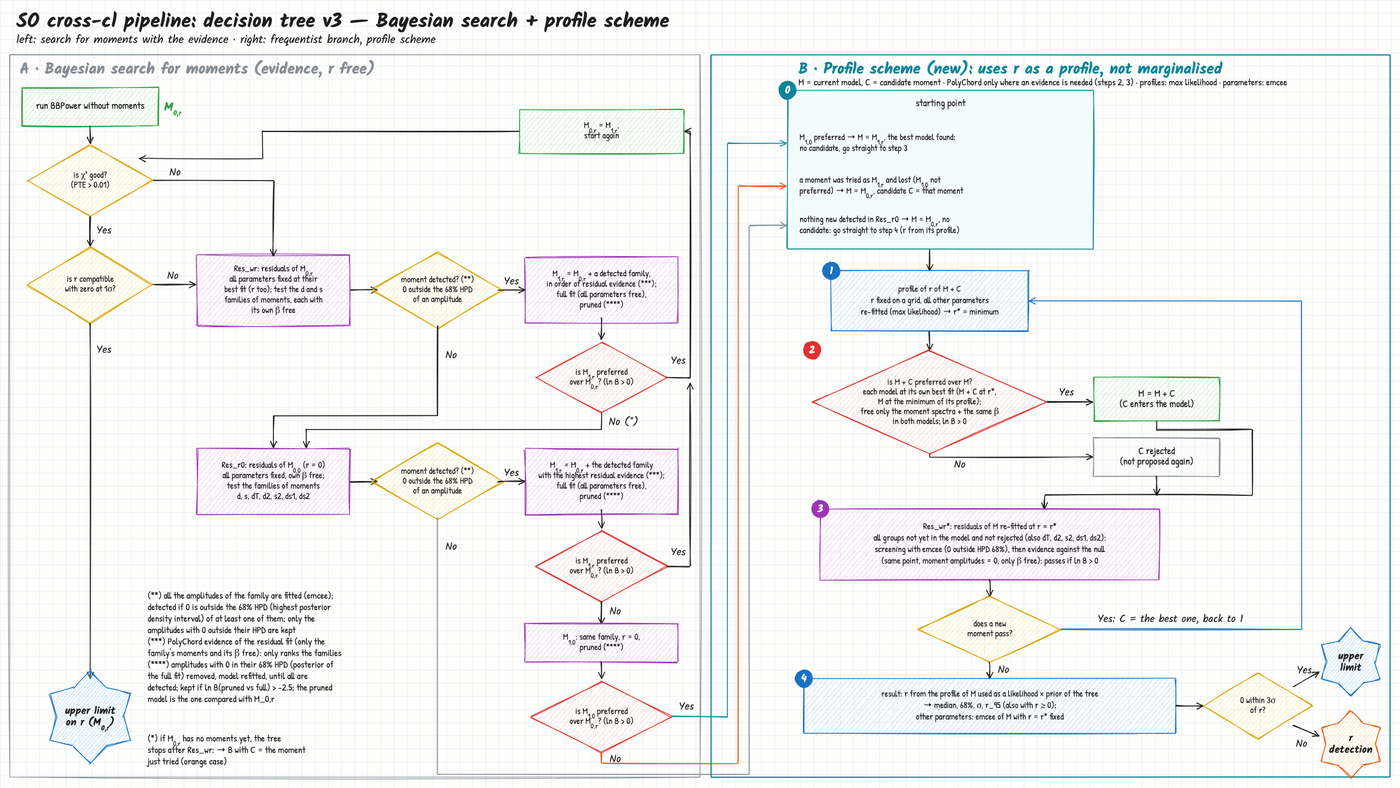

**Profile scheme**

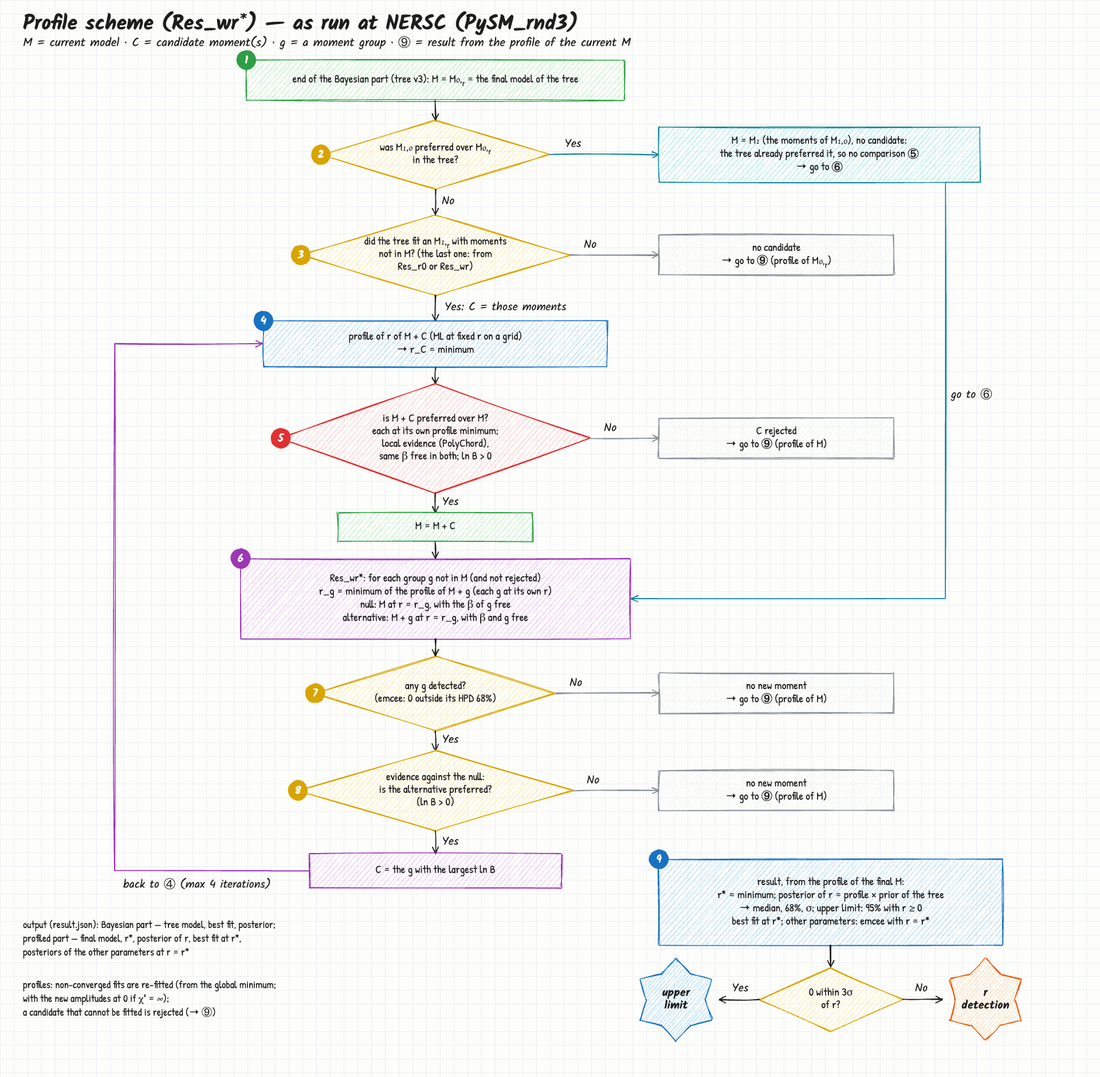

## 0. Setup

In [ ]:
import json
import os

import healpy as hp
import numpy as np
import matplotlib.pyplot as plt
import sacc
import yaml

import bbsure
from bbsure.paths import DATA_DIR

REPO = os.path.dirname(os.path.dirname(os.path.abspath(bbsure.__file__)))
WORK = os.path.abspath('tutorial_run')      # all the output of this notebook
os.makedirs(WORK, exist_ok=True)

import bbpower    # the BBPower fork with the moment expansion (branch Bsure)
%matplotlib inline
print('BBSure :', REPO)
print('data   :', DATA_DIR)
print('output :', WORK)

## 1. The sky model

`bbsure.sims.sky` holds everything about the sky: the SO SAT bandpasses, the SEDs of
the components, their power spectra. Each component is a map times an SED: in
$\mu K_{\rm CMB}$ the CMB has SED 1, the dust is a modified black body, the
synchrotron a power law. The SEDs are integrated over the bandpasses with the same
convention as BBPower.

The Gaussian foreground model has power-law spectra,
$D_\ell = A\,(\ell/80)^\alpha$, and its parameters live in `FG_PARAMS`. We load the
values fitted on PySM d1s1 in the SO patch: the same model used for the covariance
sims.

In [ ]:
from bbsure.sims import sky

sky.load_fg_params(os.path.join(REPO, 'configs', 'fg_params_d1s1_hits_n128.yml'))
print(sky.BAND_NAMES)

`get_seds()` returns the SED matrix [component, band]: how much of each component
(in units of its amplitude at the reference frequency) ends up in each band.

In [ ]:
seds = sky.get_seds()
nu = [27, 39, 93, 145, 225, 280]           # band centres [GHz]

plt.figure(figsize=(6, 4))
for row, name in zip(seds, ['CMB', 'dust (353 GHz)', 'synchrotron (23 GHz)']):
    plt.loglog(nu, row, 'o-', label=name)
plt.xlabel(r'$\nu$ [GHz]'); plt.ylabel('SED in each band')
plt.legend(); plt.show()

The power spectra: CMB (lensing plus a tensor part proportional to $r$) and the
Gaussian dust and synchrotron, at their reference frequencies.

In [ ]:
lmax = 383
ell = np.arange(lmax + 1)
dl = ell * (ell + 1) / (2 * np.pi)

_, bb_r0 = sky.get_cmb_spectra(lmax, r=0.)
_, bb_r1 = sky.get_cmb_spectra(lmax, r=0.01)
_, dust_bb, _, synch_bb = sky.get_fg_spectra(lmax)

plt.figure(figsize=(7, 4.5))
plt.loglog(ell, dl * bb_r0, label='CMB lensing')
plt.loglog(ell, dl * (bb_r1 - bb_r0), label='CMB tensor, r = 0.01')
plt.loglog(ell, dl * dust_bb, label='dust at 353 GHz')
plt.loglog(ell, dl * synch_bb, label='synchrotron at 23 GHz')
plt.xlim(2, lmax); plt.xlabel(r'$\ell$'); plt.ylabel(r'$D_\ell^{BB}$ [$\mu$K$^2$]')
plt.legend(); plt.show()

### Moments

If the spectral index varies across the sky, $\beta(\hat n) = \beta_0 + \delta\beta(\hat n)$,
the dust map at frequency $\nu$ is, to second order,

$$d_\nu(\hat n) = A(\hat n)\left[f(\nu) + \delta\beta\,\partial_\beta f + \tfrac12\,\delta\beta^2\,\partial^2_\beta f\right].$$

The derivatives of the SED integrated over the bandpasses tell how much each
**moment map** ($A\,\delta\beta$, $A\,\delta\beta^2$, ...) contributes to each band:

In [ ]:
S1, S2 = sky.get_dust_beta_derivs()
plt.figure(figsize=(6, 4))
plt.semilogx(nu, seds[1], 'o-', label=r'$f$ (dust SED)')
plt.semilogx(nu, S1, 'o-', label=r'$\partial_\beta f$')
plt.semilogx(nu, S2, 'o-', label=r'$\partial^2_\beta f$')
plt.axhline(0, color='grey', lw=0.5)
plt.xlabel(r'$\nu$ [GHz]'); plt.legend(); plt.show()

## 2. Simulating the observed maps

`bbsure.sims.maps.generate_maps` makes the maps of one realization: CMB, foregrounds,
the SAT beams and SO V3 noise, written as one file per split (4 splits), each with
Q and U in the 6 bands.

As a quick example we simulate a **Gaussian** sky at low resolution with a dust
moment: a Gaussian map $\delta\beta(\hat n)$ with power spectrum
$10^{-6}\,{\rm amp}\,(\ell/80)^\gamma$, applied pixel by pixel. This takes a few
seconds.

In [ ]:
from bbsure.sims.maps import generate_maps

generate_maps(seed=1, nside=64, output_dir=os.path.join(WORK, 'maps_gauss'),
              r=0.01, amp_beta=0.5, gamma_beta=-3.)

In [ ]:
dbeta = hp.read_map(os.path.join(WORK, 'maps_gauss', 'dbeta.fits.gz'))
obs = hp.read_map(os.path.join(WORK, 'maps_gauss', 'obs_split1of4.fits.gz'), field=None)

fig = plt.figure(figsize=(12, 4))
hp.mollview(dbeta, title=r'$\delta\beta$ of the dust', fig=fig.number, sub=121)
# rows of the file: Q, U of each band in order -> MF2 (145 GHz) Q is row 2 * 3
hp.mollview(obs[2 * 3], title=r'Q at 145 GHz, split 1 [$\mu$K]', fig=fig.number, sub=122)
plt.show()

The data set of this tutorial was made in the same way, at nside 128 with the PySM
d12s5 foregrounds instead of the Gaussian ones (PySM at nside 512, then downgraded
in harmonic space), the noise following the SO hits map and the E modes of the
signal removed. It needs the PySM templates and takes a few minutes:

In [ ]:
# generate_maps(seed=7047, nside=128, output_dir=os.path.join(WORK, 'maps_d12s5'),
#               r=0.01113176, pysm='d12s5', pysm_nside_in=512,
#               hits_noise=os.path.join(DATA_DIR, 'masks', 'norm_nHits_SA_35FOV_G_nside128.fits'),
#               sens_mode=2, one_over_f=0, kludge=False, no_ee=True)

## 3. From maps to power spectra

BBPower computes the spectra in two stages:

- **BBPowerSpecter**: all the cross-spectra between bands and splits (NaMaster, with
  the hits-weighted mask `data/masks/mask_hits_C2_7deg_nside128.fits.gz` and B-mode
  purification);
- **BBPowerSummarizer**: the cross-split coadded spectra (no noise bias), the noise
  spectra and the **covariance**, estimated from simulations.

The covariance comes from 500 Gaussian sims of a fiducial sky (foregrounds fitted on
PySM d1s1, $r = 0$). They are generated and their spectra computed once, then reused
for every data set; the same sky gives the fiducial spectra of the Hamimeche-Lewis
likelihood. `scripts/run_spectra.sh` runs the two BBPower stages. All this takes
several CPU hours:

In [ ]:
# # 500 covariance sims (Gaussian foregrounds of section 1) ...
# sky.load_fg_params(os.path.join(REPO, 'configs', 'fg_params_d1s1_hits_n128.yml'))
# for seed in range(5002, 5502):
#     generate_maps(seed, 128, os.path.join(WORK, 'sims_cov', f's{seed}'), r=0.,
#                   hits_noise=os.path.join(DATA_DIR, 'masks', 'norm_nHits_SA_35FOV_G_nside128.fits'),
#                   sens_mode=2, one_over_f=0, kludge=False, no_ee=True)
# with open(os.path.join(WORK, 'sims_cov', 'sims_list.txt'), 'w') as f:
#     f.writelines(os.path.join(WORK, 'sims_cov', f's{seed}') + '\n' for seed in range(5002, 5502))
#
# # ... their spectra, together with those of the data set (and the data vector)
# !bash {REPO}/scripts/run_spectra.sh --maps {WORK}/maps_d12s5 --out {WORK}/spectra_d12s5 \
#     --cov-maps {WORK}/sims_cov/sims_list.txt
#
# # fiducial spectra of the HL likelihood (the BBPower model at the parameters of the sims)
# !python {REPO}/scripts/make_fiducial.py --fg-params {REPO}/configs/fg_params_d1s1_hits_n128.yml \
#     --base-config {REPO}/configs/base_config_tree.yml --cells {WORK}/spectra_d12s5 \
#     --out {WORK}/cls_fid.fits

The output, reduced to BB, is in `data/examples/d12s5_s7047/`: `cells_coadded.fits`
(data vector and covariance) and `cells_noise.fits`. They are
[sacc](https://github.com/LSSTDESC/sacc) files:

In [ ]:
EXAMPLE = os.path.join(DATA_DIR, 'examples', 'd12s5_s7047')
data = sacc.Sacc.load_fits(os.path.join(EXAMPLE, 'cells_coadded.fits'))
bands = sorted(data.tracers)
name = dict(zip(bands, sky.BAND_NAMES))
print(len(data.mean), 'data points; covariance', data.covariance.covmat.shape)

In [ ]:
err = np.sqrt(np.diag(data.covariance.covmat))
plt.figure(figsize=(7, 4.5))
for b in bands:
    ell, cl, ind = data.get_ell_cl('cl_bb', b, b, return_ind=True)
    ok = (ell >= 30) & (ell <= 250)              # multipoles used by the fit
    plt.errorbar(ell[ok], cl[ok], err[ind][ok], fmt='o', ms=3, label=name[b])
plt.yscale('symlog', linthresh=1e-3); plt.xscale('log')
plt.xlabel(r'$\ell$'); plt.ylabel(r'$D_\ell^{BB}$ [$\mu$K$^2$]')
plt.title('BB auto-spectra of the example'); plt.legend(); plt.show()

## 4. The models of the tree

The tree fits the data with BBPower's BBCompSep, which supports the moment expansion
in the formalism of Vacher et al. 2022: each **moment map**
$w_{nm} = A\,\delta\beta^n\,\delta(1/T)^m$ of a component gets a free cross-spectrum
$A_{w_a w_b}\,(\ell/80)^{\alpha_{w_a w_b}}$. The tree switches these spectra on in
**groups**:

In [ ]:
from bbsure.models import MOMENT_GROUPS

for g, G in MOMENT_GROUPS.items():
    spectra = ', '.join(f"A_{G['pref']}_{s}" for s in G['spectra'])
    print(f"{g:4s} {spectra:40s} frees {G['free']}")

A `Model` says which groups are on and whether $r$ is free. Its label is used
everywhere (logs, directories):

In [ ]:
from bbsure.models import Model

M0 = Model()                              # nominal model, r free
M1 = M0.plus('d')                         # + first-order dust moment
print(M0.label, M1.label, M1.with_r(False).label)
print('moment amplitudes of', M1.label, ':', M1.amplitudes())

Every fit is a variant of one BBPower config, `configs/base_config_tree.yml`, which
holds all the parameters and their priors. `build_config` switches off the moment
spectra of the groups that are not in the model ($A = 0$) and fixes $r$ if needed:

In [ ]:
from bbsure.config import build_config, free_param_names
from bbsure.paths import load_yaml

base = load_yaml(os.path.join(REPO, 'configs', 'base_config_tree.yml'))
for M in (M0, M1, M1.with_r(False)):
    cfg = build_config(base, M, 'maximum_likelihood')
    print(f"{M.label:10s}", free_param_names(cfg['BBCompSep']))

## 5. The decision tree

The tree needs a configuration: where the data are, the thresholds of the decisions,
the groups tested in the residuals and the samplers. We take the one of the
validation and point it to the example; PolyChord runs with MPI on half of the cores
of this machine.

In [ ]:
TREE = os.path.join(WORK, 'tree')        # one directory per BBCompSep run + the logs

tpl = open(os.path.join(REPO, 'configs', 'tree_config_template.yml')).read()
tc = yaml.safe_load(tpl.replace('@REPO@', REPO).replace('@DATA@', DATA_DIR)
                       .replace('@RUN@/output', EXAMPLE).replace('@RUN@', WORK))
tc['polychord']['mpi_procs'] = max(1, os.cpu_count() // 2)
del tc['polychord']['mpi_launcher']    # srun on the cluster, mpirun here
os.environ['BBPOWER_NPROC'] = str(max(1, os.cpu_count() // 2))   # emcee pool

print(yaml.safe_dump({k: tc[k] for k in ('thresholds', 'moments')}, sort_keys=False))

- `pte_min`: the $\chi^2$ is good if PTE > 0.01;
- `lnB_preferred`: a model is preferred if $\ln B > 0$ (PolyChord evidences);
- `hpd_frac`: a moment is detected in the residuals if zero is outside the 68% HPD
  interval of one of its amplitudes;
- `res_wr` / `res_r0`: groups tested on the residuals of the current model with
  everything fixed at its best fit ($r$ included) / with $r = 0$.

The tree is built from three objects:

- `BBCompSepRunner` runs BBCompSep (ML fits in this process, PolyChord and emcee as
  separate processes). Every run has its own directory with its config: **a run with
  the same config is never repeated**, so an interrupted tree restarts where it
  stopped;
- `Fitter` turns runs into the operations of the tree: full fit (ML + PolyChord),
  screening (ML + emcee), residual test of a group;
- `DecisionLog` records every node.

In [ ]:
from bbsure.fitter import Fitter
from bbsure.log import DecisionLog
from bbsure.runner import BBCompSepRunner
from bbsure.tree import DecisionTree

os.makedirs(TREE, exist_ok=True)
log = DecisionLog(TREE)
fitter = Fitter(BBCompSepRunner(tc, log), hpd_frac=tc['thresholds']['hpd_frac'])
tree = DecisionTree(tc, fitter, log)

Now the tree runs: every node is printed (and written in `tutorial_run/tree/decision_log.txt`).
**This takes a few hours.**

In [ ]:
%%time
result = tree.run()
json.dump(result, open(os.path.join(TREE, 'conclusion_tree.json'), 'w'), indent=2)
result

## 6. The profile scheme

The tree compares models with the Bayesian evidence over the whole prior of $r$. A
moment that is degenerate with $r$ can then be rejected because it competes with $r$,
or adopted only at $r = 0$ ($M_{1,0}$ preferred). The profile scheme starts from the
concluded tree and tests each candidate at its own $r$, the minimum of its profile
likelihood; the result is the profile of the final model, used as the likelihood of
$r$ (see the flowchart at the top).

`ProfileScheme` reads the concluded tree from its directory. **This takes about an
hour.**

In [ ]:
%%time
from bbsure.profile_scheme import ProfileScheme

PROF = os.path.join(TREE, 'profile')
scheme = ProfileScheme(tc, TREE, PROF)
prof = scheme.run()
print(prof['conclusion'], prof['model_final'])

## 7. Results

The path through the flowchart:

In [ ]:
print(open(os.path.join(TREE, 'decision_log.txt')).read())

$r$ from the two parts of the pipeline: the **Bayesian** posterior of the model chosen
by the tree (PolyChord, marginalized over everything else), and the posterior from the
**profile** likelihood of the final model of the scheme (true $r$ = 0.0111):

In [ ]:
r_true = 0.01113176
b = prof['bayes']['posterior']['r_tensor']
print(f"tree    ({prof['model_tree']}):  r = {b['med']:.4f} +- {b['std']:.4f}")
print(f"profile ({prof['model_final']}):  r = {prof['r_med_pl']:.4f} +- {prof['r_std_pl']:.4f}"
      f"   (r* = {prof['r_star_final']:.4f})")
print('conclusion:', prof['conclusion'])

In [ ]:
# Bayesian posterior: PolyChord samples of the model of the tree
pc = os.path.join(TREE, prof['model_tree'] + '_PC')
names = free_param_names(yaml.safe_load(open(os.path.join(pc, 'config.yml')))['BBCompSep'])
r_tree = np.loadtxt(os.path.join(pc, 'polychord', 'pch_equal_weights.txt'))[:, 2 + names.index('r_tensor')]

# profile of the final model: chi2(r), and exp(-Delta chi2 / 2) as the posterior
p = np.load(os.path.join(PROF, f"profile_{prof['model_final']}.npz"))
r, dchi2 = p['r'], p['chi2'] - p['chi2'].min()
post = np.exp(-dchi2 / 2) / np.trapezoid(np.exp(-dchi2 / 2), r)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].hist(1e3 * r_tree, 40, density=True, histtype='step', lw=2, label='tree (Bayesian)')
ax[0].plot(1e3 * r, post / 1e3, lw=2, label='profile scheme')
ax[1].plot(1e3 * r, dchi2, 'o-'); ax[1].set_ylim(0, 16); ax[1].set_ylabel(r'$\Delta\chi^2$')
ax[1].set_title(f"profile likelihood of {prof['model_final']}")
for a in ax:
    a.axvline(1e3 * r_true, color='k', lw=1, label='true r')
    a.set_xlabel(r'$r\ [10^{-3}]$')
ax[0].legend(); plt.show()

## Next steps

- **Many data sets**: `scripts/make_plan.py` draws seeds, skies and $r$; `nersc/` runs
  one tree per set on Perlmutter; `scripts/collect.py` collects the results and `plots/`
  makes the tables and figures of the validation.
- **From the command line**, sections 5 and 6 are `python scripts/run_tree.py --config
  <tree config>` with `run: profile_scheme: true`.
- **Tests** of the logic without BBCompSep: `tests/test_decision_tree.py`,
  `tests/test_profile_scheme.py`.